In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.Robusted_filas import robust_archetypal_analysis
from src.Robusted_mxnx1 import robust_archetypal_analysis_mxnx1
from src.Robusted_Chen_2D_mxnx1 import robust_archetypal_analysis_huber, robust_archetypal_analysis_huber_mxnx1

np.set_printoptions(precision=4, suppress=True)

In [2]:
# Datos con menor separación entre arquetipos y adición de ruido
rng = np.random.default_rng(42)

# Arquetips verdaders principals
true_Z = np.array([
    [0.0, 0.0],
    [0.4, 0.05],
    [0.15, 0.45]
])

n_regular = 135
n_outliers = 15
n_samples = n_regular + n_outliers

# Generar punts regulars dins l'envolupant dels arquetips
true_S_reg = rng.dirichlet(np.ones(3), size=n_regular)
X_regular = true_S_reg @ true_Z
X_regular += rng.normal(0, 0.02, size=X_regular.shape)  # Soroll gaussià

# Generar outliers allunyats en diferents regions/quadrants
outliers_g1 = rng.uniform(low=[0.6, 0.6], high=[0.9, 0.8], size=(5, 2))     # A dalt a la dreta
outliers_g2 = rng.uniform(low=[-0.4, 0.3], high=[-0.2, 0.6], size=(5, 2))   # A dalt a l'esquerra
outliers_g3 = rng.uniform(low=[0.1, -0.4], high=[0.4, -0.2], size=(5, 2))   # A baix al centre

X_outliers = np.vstack([outliers_g1, outliers_g2, outliers_g3])

# Combinar totes les observacions
X = np.vstack([X_regular, X_outliers])
p = 3

# Definir pesos baixos als outliers lectors
center = np.mean(true_Z, axis=0)
dist_to_center = np.linalg.norm(X - center, axis=1)

weights = np.ones(n_samples)
outlier_indices = np.argsort(dist_to_center)[-n_outliers:]
weights[outlier_indices] = rng.uniform(0.05, 0.2, size=n_outliers)

W = np.diag(weights)

print("Dimensiones de X:", X.shape)
print("Número de arquetipos p:", p)
print("Puntos regulares (peso 1.0):", np.sum(weights == 1.0))
print("Outliers (pesos bajos <= 0.2):", np.sum(weights <= 0.2))

Dimensiones de X: (150, 2)
Número de arquetipos p: 3
Puntos regulares (peso 1.0): 135
Outliers (pesos bajos <= 0.2): 15


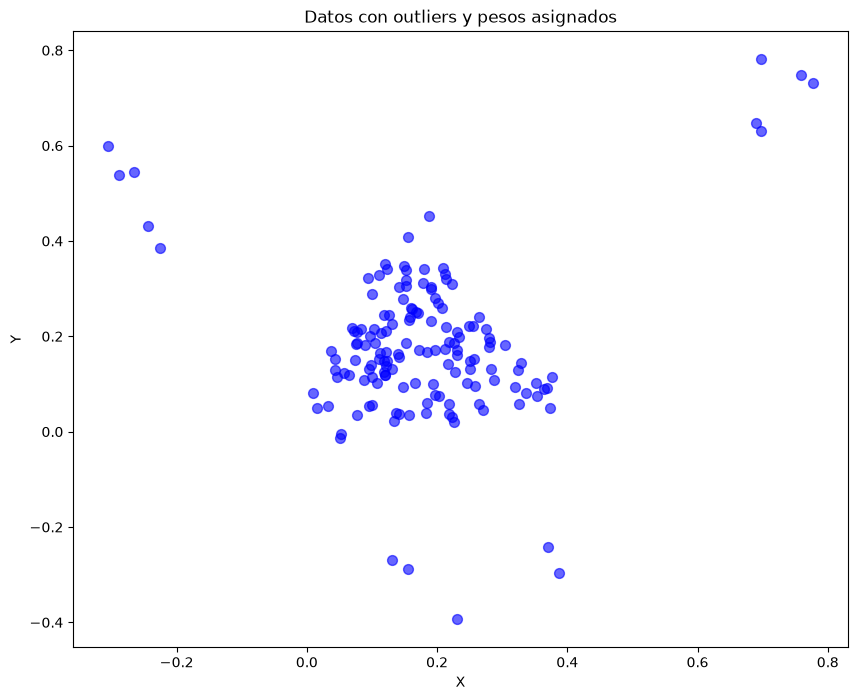

In [3]:
# plot data

plt.figure(figsize=(10, 8))

plt.scatter(X[:, 0], X[:, 1], c='blue', alpha=0.6, s=50)

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Datos con outliers y pesos asignados')

plt.show()

In [4]:
# Métodos

# A) AA-robusto (IRLS con estimadores M / Bisquare de Eugster & Leisch 2011)
C_rob, S_rob, Z_rob, weights_rob = robust_archetypal_analysis(
    W @ X, p=p, max_robust_iter=20, max_inner_iter=10, c_factor=2.0, tol=1e-5, w_init=weights,
    random_state=42, verbose=False
)

# B) AA-robusto (IRLS con estimadores M / Bisquare de Eugster & Leisch 2011)
# Ahora capturamos X_weighted_3d como 5º valor devuelto por la función
C_rob_mxnx1, S_rob_mxnx1, Z_rob_mxnx1, weights_rob_mxnx1, X_weighted_3d = robust_archetypal_analysis_mxnx1(
    W @ X, p=p, max_robust_iter=20, max_inner_iter=10, c_factor=2.0, tol=1e-5, w_init=weights,
    random_state=42, verbose=False
)

# C) AA-robusto (Algoritmo 3 de Chen et al. 2014 con pérdida de Huber)
C_rob, S_rob_huber, Z_rob_huber, weights_rob_huber = robust_archetypal_analysis_huber(
    W @ X, p=p, max_robust_iter=20, epsilon=0.01, tol=1e-5,
    random_state=42, verbose=False
)

# D) AA-robusto (Algoritmo 3 de Chen et al. 2014 con formato (m, n, 1))
# Capturamos X_weighted_3d como 5º valor devuelto
C_rob_mxnx1, S_rob_huber_mxnx1, Z_rob_huber_mxnx1, weights_rob_huber_mxnx1, X_weighted_3d_huber = robust_archetypal_analysis_huber_mxnx1(
    W @ X, p=p, max_robust_iter=20, epsilon=0.01, tol=1e-5,
    random_state=42, verbose=False
)

print("Ejecución completada.")

Ejecución completada.


In [5]:
# Comparación cuantitativa de los métodos
def sse(X_true, X_hat):
    return float(np.sum((X_true - X_hat) ** 2))

def weighted_sse(X_true, X_hat, w):
    # Si w tiene 3 dimensiones (m, n, 1), colapsamos el canal 3D para la ponderación
    if w.ndim == 3:
        w = w.squeeze(axis=-1)
    
    # Si w es un vector 1D (m,), expandimos dimensiones para broadcasting
    if w.ndim == 1:
        w = w[:, None]

    # Pesos por observación: cada residuo de fila se multiplica por w_i.
    return float(np.sum(w[:, None] * (X_true - X_hat) ** 2))

Xhat_rob = S_rob @ Z_rob
Xhat_rob_mxnx1 = S_rob_mxnx1 @ Z_rob_mxnx1
Xhat_rob_huber = S_rob_huber @ Z_rob_huber
Xhat_rob_huber_mxnx1 = S_rob_huber_mxnx1 @ Z_rob_huber_mxnx1

results = [
    {"Método": "AA-Robusto (Bisquare)", "Ponderado": "Adaptativo (M-est)", "SSE común": sse(X, Xhat_rob),
     "SSE ponderado": weighted_sse(X, Xhat_rob, weights_rob), "Iteraciones/loss final": sse(X, Xhat_rob)},
    {"Método": "AA-Robusto (Bisquare) mxnx1", "Ponderado": "Adaptativo (M-est)", "SSE común": sse(X, Xhat_rob_mxnx1),
     "SSE ponderado": weighted_sse(X, Xhat_rob_mxnx1, weights_rob_mxnx1), "Iteraciones/loss final": sse(X, Xhat_rob_mxnx1)},
    {"Método": "AA-Robusto (Huber)", "Ponderado": "Adaptativo (M-est)", "SSE común": sse(X, Xhat_rob_huber),
     "SSE ponderado": weighted_sse(X, Xhat_rob_huber, weights_rob_huber), "Iteraciones/loss final": sse(X, Xhat_rob_huber)},
    {"Método": "AA-Robusto (Huber) mxnx1", "Ponderado": "Adaptativo (M-est)", "SSE común": sse(X, Xhat_rob_huber_mxnx1),
     "SSE ponderado": weighted_sse(X, Xhat_rob_huber_mxnx1, weights_rob_huber_mxnx1), "Iteraciones/loss final": sse(X, Xhat_rob_huber_mxnx1)},
]

comparison = pd.DataFrame(results)
display(comparison.round(6))

,Método,Ponderado,SSE común,SSE ponderado,Iteraciones/loss final
0,AA-Robusto (Bisquare),Adaptativo (M-est),6.353108,952.490498,6.353108
1,AA-Robusto (Bisquare) mxnx1,Adaptativo (M-est),6.353108,952.490498,6.353108
2,AA-Robusto (Huber),Adaptativo (M-est),6.668445,730.667536,6.668445
3,AA-Robusto (Huber) mxnx1,Adaptativo (M-est),6.668445,730.667536,6.668445


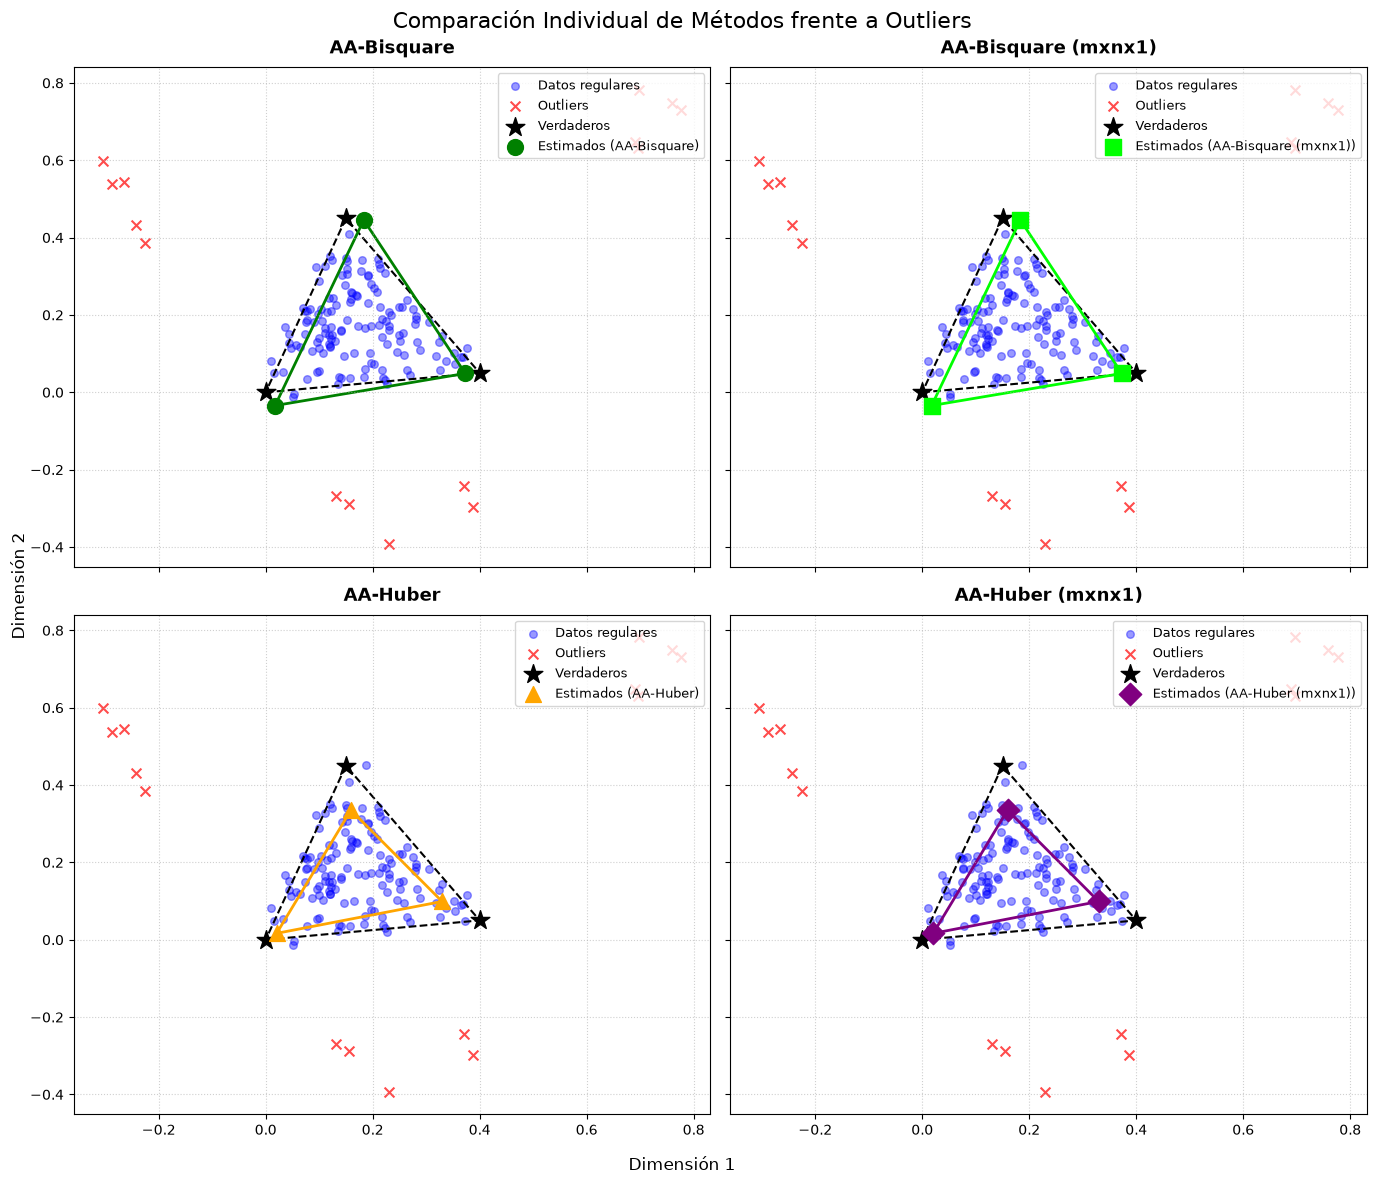

In [6]:
# Definición de las soluciones de los métodos a evaluar
methods_Z = [
    ("AA-Bisquare", Z_rob, "green", "o"),
    ("AA-Bisquare (mxnx1)", Z_rob_mxnx1, "lime", "s"),
    ("AA-Huber", Z_rob_huber, "orange", "^"),
    ("AA-Huber (mxnx1)", Z_rob_huber_mxnx1, "purple", "D"),
]

# Crear una figura con una cuadrícula de 2x2 para cada método
fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharex=True, sharey=True)
axes = axes.flatten()

# Máscaras para diferenciar datos
regular_mask = weights > 0.2
outlier_mask = weights <= 0.2

for idx, (name, Z_est, color, marker) in enumerate(methods_Z):
    ax = axes[idx]

    # 1. Puntos de datos y Outliers
    ax.scatter(
        X[regular_mask, 0],
        X[regular_mask, 1],
        c="blue",
        alpha=0.4,
        s=30,
        label="Datos regulares",
    )
    ax.scatter(
        X[outlier_mask, 0],
        X[outlier_mask, 1],
        c="red",
        alpha=0.7,
        s=50,
        marker="x",
        label="Outliers",
    )

    # 2. Arquetipos Verdaderos (Generadores)
    ax.scatter(
        true_Z[:, 0],
        true_Z[:, 1],
        c="black",
        marker="*",
        s=200,
        zorder=5,
        label="Verdaderos",
    )
    poly_true = plt.Polygon(
        true_Z, fill=False, edgecolor="black", linestyle="--", linewidth=1.5
    )
    ax.add_patch(poly_true)

    # 3. Arquetipos Estimados por el método actual
    ax.scatter(
        Z_est[:, 0],
        Z_est[:, 1],
        c=color,
        marker=marker,
        s=130,
        zorder=6,
        label=f"Estimados ({name})",
    )
    poly_est = plt.Polygon(
        Z_est, fill=False, edgecolor=color, linestyle="-", linewidth=2
    )
    ax.add_patch(poly_est)

    # Ajustes del subgráfico
    ax.set_title(name, fontsize=13, fontweight="bold", pad=10)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", fontsize=9)

# Etiquetas comunes
fig.supxlabel("Dimensión 1", fontsize=12)
fig.supylabel("Dimensión 2", fontsize=12)
fig.suptitle(
    "Comparación Individual de Métodos frente a Outliers", fontsize=16, y=0.98
)

plt.tight_layout()
plt.show()